# 52 · Gráficos do mini deck

Gera os três gráficos dos slides técnicos do mini deck, a partir das tabelas já gravadas pelos notebooks
39 a 50. Nenhum dado é alterado e nenhuma conta nova é feita: os gráficos mostram o que já está decidido
em `decisoes.md`.

1. **Efeito do logaritmo**: dias sem treinar entre os assinantes ativos, antes e depois de `log(1 + x)`
   (tratamento do notebook 41).
2. **Escolha do k**: inércia e silhueta de k = 2 a 8 (notebook 50).
3. **Os quatro grupos em dois planos**: dias sem treinar × % dos treinos ao ar livre, e meses de casa ×
   treinos por semana, com a cor do segmento oficial.

Saídas: `saidas/mini_deck_log.png`, `saidas/mini_deck_curva.png` e `saidas/mini_deck_grupos.png`.
Ordem de execução: 39 → 41 → 42 → 43 → 50 → 52.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

P = Path("../dados/processados"); S = Path("../saidas")
PAPEL, TINTA, SUAVE, RISCO = "#F7F5F0", "#16202E", "#4A5568", "#C8372F"
CORES = {"Ativos ao ar livre": "#2F6DB5", "Ativos em ambiente fechado": "#16202E", "Recém-chegados": "#1E9E8A", "Esfriando": "#C8372F"}
plt.rcParams.update({"font.size": 15, "axes.edgecolor": SUAVE, "axes.labelcolor": TINTA, "xtick.color": SUAVE, "ytick.color": SUAVE,
                     "text.color": TINTA, "figure.facecolor": PAPEL, "axes.facecolor": PAPEL, "savefig.facecolor": PAPEL})
def limpa(ax):
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
def fig_px(w, h, **k):
    # tamanho em pixels do slide (1920 x 1080); gravado com o dobro da resolução
    return plt.subplots(figsize=(w / 100, h / 100), dpi=100, **k)

m = pd.read_parquet(P / "tabela_master.parquet")
ofi = pd.read_parquet(P / "segmentos_oficiais.parquet")
at = m[m.ativa_no_corte]
print("tabela master:", m.shape, "| assinantes ativos:", len(at), "| segmentos oficiais:", len(ofi))

tabela master: (63929, 119) | assinantes ativos: 14753 | segmentos oficiais: 14753


## 1. Efeito do logaritmo em dias sem treinar

ativos: 14753 -> com último treino conhecido: 14577 | máximo: 271 dias
assimetria antes: 4.41 | depois do log(1 + x): 0.98


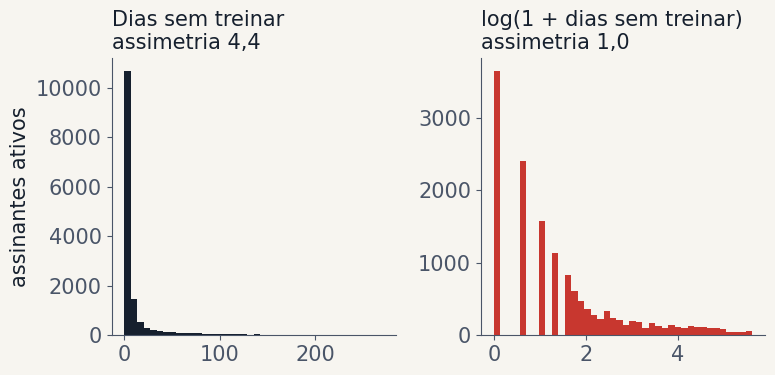

In [2]:
d = at.dias_sem_treinar.dropna().astype(float)
print("ativos:", len(at), "-> com último treino conhecido:", len(d), "| máximo:", int(d.max()), "dias")
print("assimetria antes:", round(d.skew(), 2), "| depois do log(1 + x):", round(np.log1p(d).skew(), 2))
fig, ax = fig_px(800, 400, nrows=1, ncols=2)
ax[0].hist(d, bins=40, color=TINTA); ax[0].set_title(f"Dias sem treinar\nassimetria {d.skew():.1f}".replace(".", ","), fontsize=15, loc="left")
ax[1].hist(np.log1p(d), bins=40, color=RISCO); ax[1].set_title(f"log(1 + dias sem treinar)\nassimetria {np.log1p(d).skew():.1f}".replace(".", ","), fontsize=15, loc="left")
ax[0].set_ylabel("assinantes ativos")
for a in ax: limpa(a)
fig.tight_layout(); fig.savefig(S / "mini_deck_log.png", dpi=200); plt.show()

## 2. Escolha do k: inércia e silhueta

 k   inercia  silhueta  menor_grupo
 2 47979.359     0.351         3252
 3 38466.231     0.285         3069
 4 31118.772     0.300         2092
 5 26733.908     0.310          941
 6 23240.215     0.300          938
 7 20989.291     0.312          833
 8 19166.511     0.310          833


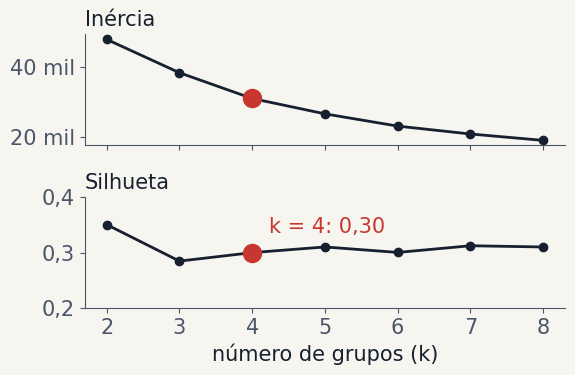

In [3]:
c = pd.read_csv(S / "segmentacao_oficial_curva.csv", encoding="utf-8-sig")
print(c[["k", "inercia", "silhueta", "menor_grupo"]].round(3).to_string(index=False))
fig, ax = fig_px(600, 400, nrows=2, ncols=1, sharex=True)
for a, col, nome in zip(ax, ["inercia", "silhueta"], ["Inércia", "Silhueta"]):
    a.plot(c.k, c[col], "o-", color=TINTA, lw=2)
    a.plot([4], [c.set_index("k").loc[4, col]], "o", color=RISCO, ms=13, zorder=3)
    a.set_title(nome, fontsize=15, loc="left"); limpa(a)
ax[0].set_yticks([20000, 40000]); ax[0].set_yticklabels(["20 mil", "40 mil"])
ax[1].set_ylim(0.2, 0.4); ax[1].set_yticks([0.2, 0.3, 0.4]); ax[1].set_yticklabels(["0,2", "0,3", "0,4"])
ax[1].annotate("k = 4: 0,30", (4, c.set_index("k").loc[4, "silhueta"]), textcoords="offset points", xytext=(12, 14), color=RISCO)
ax[1].set_xlabel("número de grupos (k)")
fig.tight_layout(); fig.savefig(S / "mini_deck_curva.png", dpi=200); plt.show()

## 3. Os quatro grupos em dois planos

Amostra de 5.000 dos 13.999 elegíveis ao k-means (semente fixa), com um pequeno deslocamento aleatório
nos pontos para não empilhar valores iguais. Eixos de dias sem treinar e meses de casa em escala
logarítmica, como no k-means.

elegíveis ao k-means: 13999 | {'Ativos ao ar livre': 5001, 'Ativos em ambiente fechado': 4030, 'Esfriando': 2876, 'Recém-chegados': 2092}
amostra: 5000 | {'Ativos ao ar livre': 1761, 'Ativos em ambiente fechado': 1450, 'Esfriando': 1025, 'Recém-chegados': 764}
pontos da amostra acima de 8 treinos por semana (fora do quadro): 15


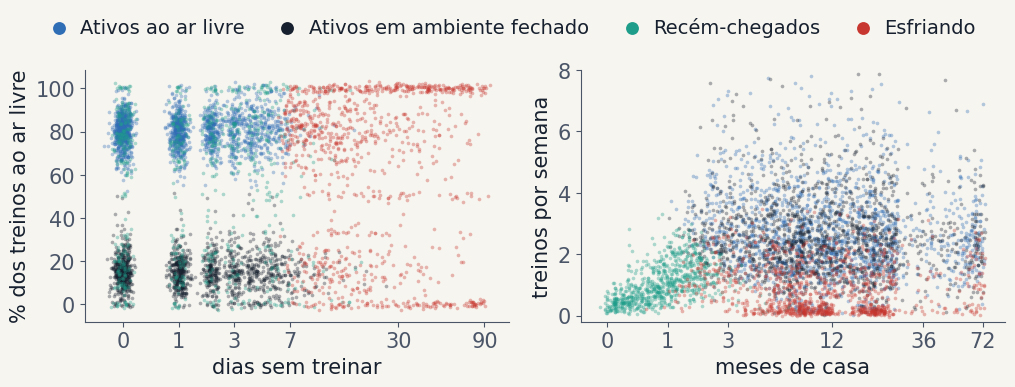

arquivos: saidas/mini_deck_log.png, mini_deck_curva.png e mini_deck_grupos.png | 0 linhas alteradas


In [4]:
e = m[m.segmento_regra == "elegível ao k-means"].merge(ofi[["user_id", "segmento"]], on="user_id")
print("elegíveis ao k-means:", len(e), "|", e.segmento.value_counts().to_dict())
assert len(e) == 13999
e["pct_ar_livre"] = e[["treinos_corrida", "treinos_caminhada", "treinos_pedal"]].sum(axis=1) / e.treinos_90d * 100
a = e.sample(5000, random_state=0)
print("amostra:", len(a), "|", a.segmento.value_counts().to_dict())
rng = np.random.default_rng(0)
jit = lambda n, s: rng.normal(0, s, n)
fig, ax = fig_px(1040, 400, nrows=1, ncols=2)
for seg, cor in CORES.items():
    g = a[a.segmento == seg]
    ax[0].scatter(np.log1p(g.dias_sem_treinar.astype(float)) + jit(len(g), 0.06), g.pct_ar_livre + jit(len(g), 1.2), s=7, color=cor, alpha=0.35, linewidths=0)
    ax[1].scatter(np.log1p(g.meses_de_casa.astype(float)) + jit(len(g), 0.02), g.treinos_por_semana.astype(float) + jit(len(g), 0.04), s=7, color=cor, alpha=0.35, linewidths=0, label=seg)
tx = [0, 1, 3, 7, 30, 90]; ax[0].set_xticks(np.log1p(tx)); ax[0].set_xticklabels(tx)
ax[0].set_xlabel("dias sem treinar"); ax[0].set_ylabel("% dos treinos ao ar livre")
tm = [0, 1, 3, 12, 36, 72]; ax[1].set_xticks(np.log1p(tm)); ax[1].set_xticklabels(tm)
ax[1].set_xlabel("meses de casa"); ax[1].set_ylabel("treinos por semana"); ax[1].set_ylim(-0.2, 8)
print("pontos da amostra acima de 8 treinos por semana (fora do quadro):", int((a.treinos_por_semana > 8).sum()))
for x in ax: limpa(x)
h, l = ax[1].get_legend_handles_labels()
leg = fig.legend(h, l, loc="upper center", ncol=4, frameon=False, fontsize=14, markerscale=3.5, handletextpad=0.1, columnspacing=1.2)
for lh in leg.legend_handles: lh.set_alpha(1)
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(S / "mini_deck_grupos.png", dpi=200); plt.show()
print("arquivos: saidas/mini_deck_log.png, mini_deck_curva.png e mini_deck_grupos.png | 0 linhas alteradas")